# 2장 2강 · 이미지 분류

## 실습 목표
- 사진 묶음이 CNN의 이미지별·클래스별 점수표가 되는 과정을 따라가고, 세 품종 소형 CNN을 실제로 학습합니다.
- 사전학습 ResNet18의 1,000개 Logit을 이미지별 확률로 바꾸고, 같은 사진의 1·2위 점수와 확률을 검산합니다.
- Oxford의 정답과 ImageNet의 예측을 이름으로 연결해 오답을 찾고, 확률 기준으로 검토 대상을 골랐을 때 생기는 누락을 설명합니다.

## 실습 환경 / 데이터
Python 3.10 이상, Jupyter, NumPy, pandas, Pillow, PyTorch, torchvision을 사용합니다. 필요한 경우 새 셀에서 %pip install numpy pandas pillow torch torchvision을 실행한 뒤 커널을 다시 시작하세요. CPU 실행이 가능합니다. ImageNet ResNet18 가중치는 첫 사용 시 약 45MB를 내려받거나 기존 캐시에서 불러옵니다.

Oxford ZIP 또는 압축을 푼 폴더를 노트북 옆에 두세요. 경로가 다르면 DATA_SOURCE를 수정하세요. 제공본에 공식 Train 원본이 없어 기존 val에 실제 파일이 있는 beagle·pug·Persian 각 20장씩을 학습용으로 사용합니다. 평가용으로는 공식 test의 같은 세 품종에서 각 20장씩 시드 42로 뽑습니다. 학습 60장과 평가 60장은 분리합니다. 평가 전에 학습을 12에포크, 예측 검토 기준을 최고 확률 80% 미만으로 고정합니다. 80%는 이 수업의 예시 기준입니다.

| 품종 | Oxford 원본 라벨 | 소형 CNN 출력 열 | ImageNet 대응 이름 |
|---|---:|---:|---|
| beagle | 4 | 0 | beagle |
| pug | 25 | 1 | pug |
| Persian | 23 | 2 | Persian cat |

## 실습 준비
아래 준비 셀은 그대로 실행하세요. 기본 CNN에는 세 개의 출력이 있고, 사전학습 모델은 1,000개 출력을 전부 사용합니다. 독립 과제는 준비 셀 후 바로 시작할 수 있습니다. 정답에는 측정값을 저장했습니다. 라이브러리 버전에 따라 마지막 소수 자리나 학습값이 조금 달라질 수 있습니다.

**재실행 안내**　필수 1의 결과를 처음부터 재현하려면 모델을 만드는 1-2 셀부터 다시 실행하세요. 이미 학습한 모델에 1-3만 반복하면 그 시점의 가중치에서 추가로 12에포크를 학습합니다.

In [1]:
from pathlib import Path, PurePosixPath
from zipfile import ZipFile
from io import BytesIO
from PIL import Image
from IPython.display import Markdown, display
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

# 제공 설정: CPU 실습에서 과도한 스레드 사용을 줄입니다.
torch.set_num_threads(2)
print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)

PyTorch: 2.10.0+cu128
torchvision: 0.25.0+cu128


In [2]:
sources = [Path("C:/Users/jihun/OneDrive/Desktop/DS 실습자료/LV2/이미지 분석/DATA/1장, 2장(1,2),3장(1),4장/Oxford/oxford_dataset/oxford_dataset.zip")]
DATA_SOURCE = next((path for path in sources if path.exists()), sources[0])

# 제공 코드: metadata.csv와 실제 이미지 파일이 있는지 확인합니다.
if not DATA_SOURCE.exists():
    raise FileNotFoundError("DATA_SOURCE를 실제 ZIP 또는 압축 해제 폴더 경로로 수정하세요.")
if DATA_SOURCE.is_file():
    with ZipFile(DATA_SOURCE) as zf:
        member_names = set(zf.namelist())
        meta_paths = sorted(n for n in member_names
                            if PurePosixPath(n).name == "metadata.csv" and "__MACOSX" not in n)
        if len(meta_paths) != 1:
            raise ValueError("metadata.csv가 하나 포함된 ZIP을 지정하세요.")
        parent = str(PurePosixPath(meta_paths[0]).parent)
        prefix = "" if parent == "." else parent + "/"
        metadata = pd.read_csv(BytesIO(zf.read(meta_paths[0])))
    def has_image(path):
        return prefix + str(path).replace("\\", "/") in member_names
    def load_rgb(path):
        with ZipFile(DATA_SOURCE) as zf:
            raw = zf.read(prefix + str(path).replace("\\", "/"))
        with Image.open(BytesIO(raw)) as im:
            return im.convert("RGB")
else:
    meta_paths = sorted(DATA_SOURCE.rglob("metadata.csv"))
    if len(meta_paths) != 1:
        raise ValueError("metadata.csv가 하나 포함된 데이터 폴더를 지정하세요.")
    data_root = meta_paths[0].parent
    metadata = pd.read_csv(meta_paths[0])
    def has_image(path):
        return (data_root / str(path)).is_file()
    def load_rgb(path):
        with Image.open(data_root / str(path)) as im:
            return im.convert("RGB")

available = metadata[metadata["image_path"].map(has_image)].copy()
pool_df = available[available["split"] == "val"].sort_values("image_path").reset_index(drop=True)
classes = ["beagle", "pug", "Persian"]
expected_imagenet = {"beagle": "beagle", "pug": "pug", "Persian": "Persian cat"}

train_rows = pool_df[pool_df.class_name.isin(classes)].copy().reset_index(drop=True)
test_pool = available[(available.split == "test") & available.class_name.isin(classes)]
test_parts = []
for name in classes:
    group = test_pool[test_pool.class_name == name].sort_values("image_path")
    test_parts.append(group.sample(n=20, random_state=42))
test_rows = pd.concat(test_parts, ignore_index=True)
to_local = {name:i for i, name in enumerate(classes)}
y_train = torch.tensor(train_rows.class_name.map(to_local).tolist(), dtype=torch.long)
y_test = torch.tensor(test_rows.class_name.map(to_local).tolist(), dtype=torch.long)
for split_rows in (train_rows, test_rows):
    assert split_rows.groupby("class_name").size().reindex(classes, fill_value=0).eq(20).all()
assert train_rows.image_id.is_unique and test_rows.image_id.is_unique
assert set(train_rows.image_id).isdisjoint(test_rows.image_id)
train_images = [load_rgb(path) for path in train_rows.image_path]
test_images = [load_rgb(path) for path in test_rows.image_path]
example_rows = train_rows.groupby("class_name", sort=False).first().loc[classes].reset_index()
example_images = [load_rgb(path) for path in example_rows.image_path]
single_image, single_row = example_images[0], example_rows.iloc[0]
def make_batch(images, preprocess):
    return torch.stack([preprocess(im) for im in images])

print("실제 JPEG 연결 행", len(available), "학습", len(train_rows), "평가", len(test_rows))
display(pd.crosstab(train_rows.class_name, train_rows.label))
display(example_rows[["image_id","class_name","label"]])

실제 JPEG 연결 행 4405 학습 60 평가 60


label,4,23,25
class_name,,,
Persian,0,20,0
beagle,20,0,0
pug,0,0,20


,image_id,class_name,label
0,beagle_110,beagle,4
1,pug_100,pug,25
2,Persian_100,Persian,23


In [3]:
# 공통 제공 코드 · 학습과 평가 반복문
def classify(model, X):
    model.eval()
    with torch.inference_mode():
        return torch.cat([model(batch).argmax(dim=1) for batch in X.split(10)])

def train_small(model, X, y):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.005)
    criterion = nn.CrossEntropyLoss()
    rng = torch.Generator().manual_seed(42)
    history = []
    model.train()
    for epoch in range(12):
        total = 0.0
        for idx in torch.randperm(len(y), generator=rng).split(10):
            optimizer.zero_grad()
            scores = model(X[idx])
            loss = criterion(scores, y[idx])
            loss.backward()
            optimizer.step()
            total += loss.item() * len(idx)
        history.append(total / len(y))
    return history

## 필수 1. 소형 CNN의 점수표 읽기와 실제 학습

1. **1-1** 세 품종의 예시 사진을 표시하고 기본 전처리(224×224 Resize, ToTensor)로 하나의 배치를 만드세요. 각 축과 dtype을 설명하세요.
2. **1-2** 시드 42에서 Conv2d(3→8, 3×3, padding=1), ReLU, AdaptiveAvgPool2d(1×1), Flatten, Linear(8→3)를 구성하세요. 세 사진의 초기 점수와 예측 번호를 출력하고 한 행을 손으로 판독하세요.
3. **1-3** 같은 기본 전처리로 학습·평가 입력을 만드세요. 제공 학습 함수로 소형 CNN을 12에포크 학습하고 첫·마지막 손실, 실제 가중치 변화와 같은 평가 60장의 학습 전후 정답 수를 기록하세요. 마지막에는 실제 품종을 행, 예측 품종을 열로 하는 3×3 표와 품종별 정답 수를 구하세요.
4. **1-4** 채널 수와 클래스 수, 학습 손실과 평가 정확도의 차이를 설명하세요. 이 모델의 공간 평균 연산이 잃을 수 있는 정보와 관측된 결과를 구분해 해석하세요.

**사진 0**　beagle_110 · beagle

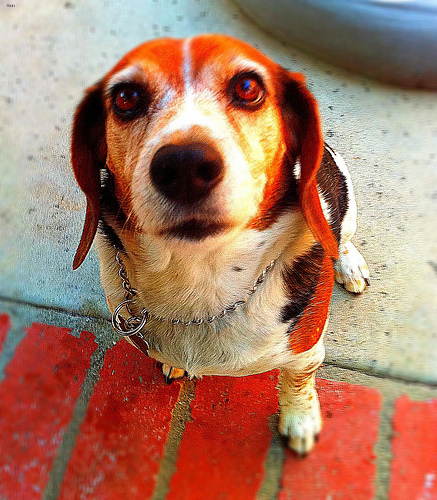

**사진 1**　pug_100 · pug

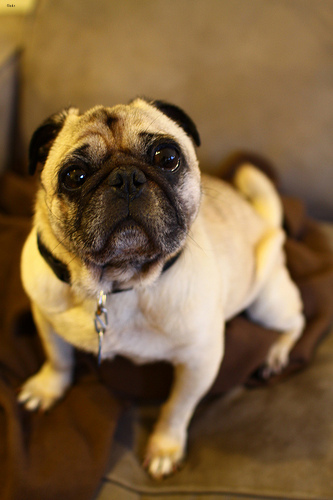

**사진 2**　Persian_100 · Persian

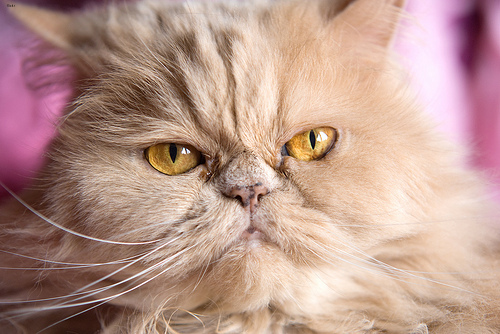

입력 Shape: torch.Size([3, 3, 224, 224])
입력 자료형: torch.float32


In [4]:
# 1-1. 요구사항에 맞게 코드를 작성하세요.
# ── 세 품종 예시 사진 표시 ──
# example_images(준비 셀): beagle·pug·Persian 순으로 한 장씩 읽은 사진 3장
for i, image in enumerate(example_images):  # enumerate: (번호 i, 사진) 쌍을 0부터 차례로 꺼냄
    display(Markdown(f"**사진 {i}**　{example_rows.iloc[i].image_id} · {example_rows.iloc[i].class_name}"))
    # f-문자열로 '사진 번호, 파일 ID, 품종'을 굵은 제목으로 표시함. iloc[i]는 i번째 행
    display(image)                           # 사진 자체를 화면에 표시함

# ── 기본 전처리 정의 ──
basic_preprocess = transforms.Compose([  # Compose: 여러 변환을 리스트 순서대로 이어 붙임
    transforms.Resize((224, 224)),       # 원본 크기가 제각각이라 모두 224×224로 맞춤
                                         # (한 묶음으로 쌓으려면 크기가 같아야 함)
    transforms.ToTensor()                # PIL 사진 → (채널 3, 높이, 너비) 텐서, 값은 0~1 실수
])
X = make_batch(example_images, basic_preprocess)
# make_batch(준비 셀): 사진마다 전처리한 뒤 torch.stack으로 맨 앞에 사진 축을 만들어 한 묶음(배치)으로 쌓음
print("입력 Shape:", X.shape)  # → (3, 3, 224, 224) = (사진 3장, RGB 채널 3, 높이, 너비)
print("입력 자료형:", X.dtype)  # → torch.float32 (32비트 실수)

### 1-1. 사진 세 장을 한 묶음으로 만들면 첫 번째 3과 두 번째 3은 무엇인가?

**정답**　입력 X의 모양은 (3, 3, 224, 224), 자료형은 torch.float32입니다. 첫 번째 3은 사진 수, 두 번째 3은 한 사진의 빨강·초록·파랑 채널 수입니다.

| X의 첫 축에서 고른 위치 | 실제 파일 | 그 자리에서 읽는 내용 |
|---|---|---|
| X[0] | beagle_110.jpg | 비글 사진 한 장의 RGB 세 채널 |
| X[1] | pug_100.jpg | 퍼그 사진 한 장의 RGB 세 채널 |
| X[2] | Persian_100.jpg | 페르시안고양이 사진 한 장의 RGB 세 채널 |

**코드를 따라가기**　for문에서 사진과 파일명을 함께 표시하는 이유는 나중에 점수표의 첫 행이 어떤 사진인지 확인하기 위해서입니다. Resize는 각 원본을 224 × 224로 바꿉니다. ToTensor는 RGB 채널을 맨 앞에 두고, 8비트 채널 값을 255로 나눠 0~1 실수로 표현합니다. 사진마다 (3, 224, 224)가 된 다음 make_batch의 torch.stack이 사진 번호를 나타내는 축을 맨 앞에 만듭니다. **X[0, 0]**은 첫 사진의 빨강 채널 한 장이고, **X[0, :, 0, 0]**은 첫 사진 왼쪽 위 한 위치의 세 색 성분입니다.

예를 들어 사진을 한 장만 더 넣으면 입력은 (4, 3, 224, 224)가 됩니다. 품종 수나 RGB 색 성분을 바꾼 것이 아니므로 두 번째 3은 그대로입니다. 반대로 같은 세 장을 다른 순서로 넣으면 모양은 같아도 출력 행과 실제 파일의 대응이 달라집니다.

**코드와 숫자 연결**　동일한 크기의 텐서 세 개를 `stack`하면 사진 축이 새로 생깁니다. 이 배치가 담은 수는 3장 × 3채널 × 224행 × 224열 = 451,584개입니다. `float32`의 32는 실수 하나를 저장하는 비트 수입니다. 좌표 (0, 0)의 채널값을 읽으려면 먼저 사진 번호를 골라야 한다는 점이 한 장만 다룰 때와 다릅니다.

In [5]:
# 1-2. 요구사항에 맞게 코드를 작성하세요.
torch.manual_seed(42)  # 무작위 초기 가중치를 재현할 수 있게 고정
# ── 소형 CNN 구성: nn.Sequential은 층을 적힌 순서대로 통과시킴 (아래 N은 사진 수) ──
small_model = nn.Sequential(
    nn.Conv2d(3, 8, kernel_size=3, padding=1),  # RGB 3채널 → 3×3 필터 8개, padding=1이라 크기 유지
                                                # → (N, 8, 224, 224)
    nn.ReLU(),                                  # 음수 반응을 0으로 바꿈
    nn.AdaptiveAvgPool2d((1, 1)),               # 채널마다 224×224 위치를 평균 하나로 요약 → (N, 8, 1, 1)
    nn.Flatten(),                               # 사진 축은 남기고 나머지를 펼침 → (N, 8)
    nn.Linear(8, 3)                             # 특징 8개 → 품종 점수 3개 (beagle, pug, Persian 순) → (N, 3)
)
small_logits = small_model(X)  # 사진 3장을 한 번에 넣음 → (3, 3) = (사진 3장, 품종 3개) 점수표
print("소형 CNN:", small_model)
print("출력 Shape:", small_logits.shape)
print("Logit:", small_logits.detach())
# Logit = 확률로 바꾸기 전의 원점수. detach()로 기울기 기록을 떼고 값만 출력함
print("초기 예측 열", small_logits.argmax(dim=1).tolist())
# argmax(dim=1): 각 행(사진)에서 가장 큰 점수의 열 번호 → [1, 1, 1]
# 세 장 모두 classes[1] = pug로 예측함 (학습 전 무작위 가중치의 결과)

소형 CNN: Sequential(
  (0): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): AdaptiveAvgPool2d(output_size=(1, 1))
  (3): Flatten(start_dim=1, end_dim=-1)
  (4): Linear(in_features=8, out_features=3, bias=True)
)
출력 Shape: torch.Size([3, 3])
Logit: tensor([[-0.2593,  0.3264, -0.0769],
        [-0.2246,  0.3144, -0.0857],
        [-0.2727,  0.3399, -0.0698]])
초기 예측 열 [1, 1, 1]


### 1-2. 마지막 층에서 사진 한 장에 점수 세 개가 생기는 과정

**정답**　초기 모델의 출력은 (3, 3)입니다. 세 행의 최고 점수 위치가 모두 1이므로 이번 실습의 품종 목록에서는 세 장 모두 pug로 예측했습니다.

| 층 | 한 배치의 모양 | 사진 한 장에서 한 일 |
|---|---|---|
| Conv2d → ReLU | (3, 8, 224, 224) | RGB 주변값을 필터 8개로 읽습니다. padding=1이라 3×3 필터를 적용해도 공간 크기는 유지됩니다. ReLU는 음수 반응을 0으로 만듭니다. |
| AdaptiveAvgPool2d((1,1)) | (3, 8, 1, 1) | 필터 하나의 224 × 224 = 50,176개 위치 반응을 평균 하나로 요약합니다. 사진마다 평균이 8개 생깁니다. |
| Flatten | (3, 8) | 사진 축은 보존하고, 각 사진의 평균 8개를 한 줄로 놓습니다. |
| Linear(8,3) | (3, 3) | 사진 한 장의 특징 8개를 조합해 beagle·pug·Persian 순으로 점수 3개를 냅니다. |

**첫 행 직접 판독**　beagle_110의 점수는 약 [−0.2593, 0.3264, −0.0769]입니다. 가장 큰 값은 가운데 0.3264입니다. 파이썬 열 번호는 0부터 시작하므로 예측 번호는 1이고 classes[1]은 pug입니다. 1은 **예측된 클래스의 번호**이지 사진 번호도, 실제 정답 번호도 아닙니다. 첫 사진의 실제 품종은 beagle이므로 이 예측은 틀렸습니다. 다음 두 행도 같은 방법으로 최대값의 열을 찾습니다.

**왜 0.3264를 32.64%라고 쓰면 안 될까요?**　이 단계의 점수는 Logit입니다. 음수가 허용되고 합이 1일 필요가 없습니다. 순위를 고를 때는 그대로 비교할 수 있습니다. 확률처럼 읽으려면 어느 클래스들과 경쟁하는지를 정한 뒤 그 축에 Softmax를 적용해야 합니다.

In [6]:
# 1-3. 요구사항에 맞게 코드를 작성하세요.
# ── 학습·평가 입력 만들기 (같은 기본 전처리 사용) ──
X_train = make_batch(train_images, basic_preprocess)  # 학습 사진 60장 → (60, 3, 224, 224)
X_test = make_batch(test_images, basic_preprocess)    # 평가 사진 60장 → (60, 3, 224, 224)

# ── 학습 전 상태 기록 ──
initial = classify(small_model, X_test)
# classify(준비 셀): 평가 모드에서 10장씩 예측 → 사진별 예측 열 번호 60개
old_weight = small_model[0].weight.detach().clone()
# small_model[0] = Sequential의 0번 층(Conv2d)
# clone()으로 별도 복사본을 만들어야 학습 후 값과 비교할 수 있음 (복사 없이 가리키기만 하면 함께 바뀜)

# ── 학습 ──
losses = train_small(small_model, X_train, y_train)
# train_small(준비 셀): Adam(lr=0.005)으로 10장씩 묶어 12에포크 학습 → 에포크별 평균 손실 12개 리스트

# ── 학습 후 상태 측정 ──
final = classify(small_model, X_test)  # 학습 후 같은 평가 60장 예측
delta = (small_model[0].weight.detach() - old_weight).abs().max().item()
# (학습 후 − 학습 전) 가중치 → 절댓값(abs) → 그중 최댓값(max) → 파이썬 숫자(item)
# 0보다 크면 가중치가 실제로 바뀌었다는 뜻
print("학습 손실(1·12에포크)", round(losses[0], 5), round(losses[-1], 5))
# losses[0] = 첫 에포크, losses[-1] = 마지막 에포크 → 1.13931, 1.1005
print("합성곱 가중치 최대 절대 변화", round(delta, 6))  # → 0.040812

# ── 학습 전후 정답 수 비교 ──
for label, pred in [("학습 전", initial), ("학습 후", final)]:
    ok = (pred == y_test).sum().item()  # 예측 == 정답이면 True(1) → 합계가 정답 수
    print(label, ok, "/", len(y_test), f"{ok/len(y_test):.2%}")  # :.2% → 백분율 소수 둘째 자리 (예: 33.33%)

# ── 품종별 정답 수 ──
for k, name in enumerate(classes):  # k = 0, 1, 2 (beagle, pug, Persian)
    subset = y_test == k            # 실제 품종이 k인 사진만 True인 마스크
    print(name, (final[subset] == k).sum().item(), "/", subset.sum().item())
    # final[subset]: 그 품종 사진들의 예측만 골라냄 → k로 맞힌 수 / 그 품종 사진 수(20)

# ── 3×3 혼동 행렬 (행: 실제 품종, 열: 예측 품종) ──
matrix = pd.crosstab(pd.Series(y_test.tolist(),name="실제"), pd.Series(final.tolist(),name="예측"))
# crosstab: (실제, 예측) 조합별 사진 수를 세는 표
matrix = matrix.reindex(index=range(3), columns=range(3), fill_value=0)
# 한 번도 나오지 않은 번호의 행·열도 0으로 채워 항상 3×3이 되게 함 (이번엔 예측이 모두 1이라 필요함)
matrix.index, matrix.columns = classes, classes  # 번호 0·1·2를 품종 이름으로 바꿈
print(matrix.to_string())                        # 대각선 칸이 품종별 정답 수

print("예측 열이 바뀐 평가 사진", (initial != final).sum().item(), "/ 60")
# 정답 수가 같아도 맞힌 사진이 달라졌을 수 있어 사진별로 비교함 → 0 / 60
display(pd.DataFrame({"epoch": range(1, len(losses) + 1), "mean_train_loss": losses}).round(5))
# 에포크 번호(1~12)와 평균 학습 손실을 표로 표시함

학습 손실(1·12에포크) 1.13931 1.1005
합성곱 가중치 최대 절대 변화 0.040812
학습 전 20 / 60 33.33%
학습 후 20 / 60 33.33%
beagle 0 / 20
pug 20 / 20
Persian 0 / 20
         beagle  pug  Persian
beagle        0   20        0
pug           0   20        0
Persian       0   20        0
예측 열이 바뀐 평가 사진 0 / 60


,epoch,mean_train_loss
0,1,1.13931
1,2,1.12003
2,3,1.11773
3,4,1.10726
4,5,1.10576
5,6,1.10465
6,7,1.10399
7,8,1.10250
8,9,1.10170
9,10,1.10083


### 1-3. 가중치는 바뀌었는데 정답 수가 그대로인 이유

**정답**　학습 전과 12에포크 후에 같은 평가 60장에서 모두 20장을 맞혔습니다(33.33%). 첫 에포크 평균 손실은 1.13931, 마지막은 약 1.10050이었고 첫 합성곱 가중치의 최대 절대 변화는 0.040812였습니다. “학습했다”와 “새 사진에서 더 많이 맞혔다”는 서로 다른 근거를 필요로 합니다.

1. 학습·평가 사진에 같은 basic_preprocess를 적용합니다. classify는 평가 모드에서 점수표의 각 행별 최대 열 번호를 구합니다. 업데이트 전 initial을 저장해 마지막 final과 동일한 정답으로 비교합니다.
2. `small_model[0].weight.detach().clone()`은 첫 합성곱의 학습 전 가중치를 별도 텐서에 복사합니다. 단순히 같은 객체를 가리키면 학습 후 양쪽이 함께 바뀌어 전후 차이를 계산할 수 없습니다.
3. train_small 안에서 60장을 10장씩 여섯 묶음으로 처리하고, 전체를 12번 돌므로 업데이트는 6 × 12 = 72번입니다. 점수와 정답 열을 CrossEntropyLoss에 넣습니다. zero_grad로 이전 기울기를 지우고, backward로 기울기를 구하고, optimizer.step으로 가중치를 바꿉니다. 첫 번째 인수는 모델이 낸 원점수이고 두 번째 인수는 정답 열을 나타내는 **0·1·2 정수 라벨**입니다. 이 손실 함수는 내부에서 각 점수를 로그 확률로 바꾸므로 모델 출력에 Softmax를 미리 적용할 필요가 없습니다.
4. 배치 손실에 사진 수를 곱해 더하고 60으로 나누므로 history에는 에포크당 사진 한 장 기준 평균 손실이 남습니다. 최대 절대 변화가 0보다 크므로 첫 합성곱에서도 적어도 한 값이 실제로 갱신됐습니다.

**3×3 표 읽기**　실제 품종은 행, 예측 품종은 열입니다. 같은 이름이 만나는 대각선이 정답이고 각 행의 합은 해당 품종의 평가 장수인 20입니다. 대각선은 beagle 0, pug 20, Persian 0이어서 (0 + 20 + 0) ÷ 60 = 33.33%입니다. 비대각선까지 보면 어떤 이름으로 잘못 보냈는지도 확인할 수 있습니다. 확률 분포나 점수 차이가 조금 움직여 손실이 줄더라도 최고 점수의 열이 바뀌지 않으면 정답 수는 그대로일 수 있습니다.

**정답 수가 같은 두 모델을 구별하는 방법**　학습 전과 후의 정답 수가 둘 다 20장이어도 맞힌 사진이 서로 다를 수 있습니다. 그래서 `(initial != final).sum()`으로 같은 사진의 예측 열이 바뀌었는지 다시 셉니다. 맨 아래의 에포크 표에서 평균 학습 손실도 읽어 보세요. 점수가 얼마나 정답 쪽으로 향했는지에 민감한 손실과, 1위만 남기는 정답 수가 서로 다른 질문에 답한다는 점을 확인할 수 있습니다.

이번 출력에서 예측 열이 바뀐 사진은 **0/60**입니다. 손실표의 11번째 에포크는 1.10000, 12번째는 1.10050입니다. 처음보다 마지막 손실이 작다는 결론과, 매 에포크마다 반드시 감소한다는 주장은 다릅니다.

### 1-4. 학습 결과에서 확인한 사실과 원인 가설 구분하기

**예시 답안**　소형 CNN에서 입력 채널 3은 RGB 측정값이고, 출력 3은 수업에서 선택한 품종 수입니다. 사진에서 관찰할 색 성분과 예측하려는 정답의 종류는 별도로 결정합니다. 가령 같은 RGB 사진으로 37개 품종을 예측한다면 입력 채널은 3이고 마지막 층의 출력은 37개여야 합니다.

**평균 풀링의 효과**　고양이 얼굴 근처에서만 강하게 반응한 필터와, 사진 전체에 약한 반응이 퍼져 있는 필터를 생각해 보세요. 두 반응 지도의 전체 평균이 같다면 평균 하나만 본 마지막 층은 두 패턴의 위치 차이를 구분할 수 없습니다. 이번 CNN은 각 사진을 단 8개 평균으로 요약합니다. 품종을 구별하는 귀 모양이나 얼굴의 부분적 무늬를 표현하기에는 한계가 있을 수 있습니다.

**어디까지 말할 수 있나?**　가중치 변화와 손실 출력은 실제 학습의 근거입니다. 별도 사진에서 비글과 페르시안을 맞힌 횟수가 각각 0회였다는 것은 관측된 실패입니다. 평균 풀링 하나가 실패의 유일한 원인인지, 표본이나 학습 일정이 얼마나 기여했는지는 이 실험으로 분리할 수 없습니다. 해설에서 “관측했다”와 “원인일 수 있다”를 구별하는 이유입니다.

### 문항별 해석 작성

**1-1 답변:** (실제 출력과 요구된 설명을 작성하세요.)

**1-2 답변:** (실제 출력과 요구된 설명을 작성하세요.)

**1-3 답변:** (실제 출력과 요구된 설명을 작성하세요.)

**1-4 답변:** (실제 출력과 요구된 설명을 작성하세요.)

---
## 필수 2. 사전학습 ResNet18 추론과 예측 확률 해석

**배경**  
준비된 `single_image`는 실제 beagle 이미지입니다. ImageNet 사전학습 ResNet18을 그대로 이용하여 이 이미지에 대한 **1,000개 클래스 점수**를 계산하려고 합니다.

**요구사항**
1. **2-1:** `ResNet18_Weights.DEFAULT`로 모델을 만들고 `eval()`을 적용하세요. `weights.transforms()`로 전처리한 이미지에 배치 차원을 추가하고, `torch.inference_mode()` 안에서 추론하세요. 입력·출력 shape를 출력하세요. 최종 분류기는 변경하지 않습니다.
2. **2-2:** Logit에서 `argmax(dim=1)`으로 예측 인덱스를 구하고 `weights.meta["categories"]`로 이름을 연결하세요. 예측 인덱스·이름·해당 Logit과 이 예제의 정답 대응 이름을 출력하세요.
3. **2-3:** `torch.softmax(logits,dim=1)`을 계산하세요. 확률의 shape·최솟값·최댓값·이미지별 합을 출력하고, 예측 클래스의 확률을 백분율로 표시하세요. 1·2위 클래스의 이름·점수·확률을 나란히 출력하세요. 두 확률의 비가 두 Logit 차이에 지수함수를 적용한 값과 일치하는지 검산하고, 순위 보존의 의미를 설명하세요.
4. **2-4:** ① eval과 inference_mode의 역할 차이 ② 이 출력이 Oxford 37품종 점수가 아닌 이유 ③ 높은 예측 확률을 실제 정답일 확률과 동일시할 수 없는 이유 ④ Oxford 37품종 전용 모델이 필요할 때의 다음 단계를 설명하세요.

**제출 결과**: 실제 사전학습 추론 코드, Logit·확률 출력, 올바른 클래스 매핑, 문항별 해석.

In [7]:
# 2-1. 요구사항에 맞게 코드를 작성하세요.
weights = ResNet18_Weights.DEFAULT  # ImageNet 사전학습 가중치 정보(가중치, 권장 전처리, 클래스 이름 목록)를 고름
model = resnet18(weights=weights)   # ResNet18 구조에 사전학습 가중치를 읽어 넣음 (마지막 층은 1,000개 클래스 그대로)
model.eval()                        # 평가 모드: BatchNorm이 저장된 통계를 쓰는 등 추론용으로 동작함
preprocess = weights.transforms()
# 이 가중치에 맞는 권장 전처리: 짧은 변 256 → 가운데 224×224 자르기 → 0~1 텐서 → 채널별 정규화
pretrained_X = preprocess(single_image).unsqueeze(0)
# single_image(준비 셀): beagle 예시 사진 (beagle_110)
# 전처리 결과 (3, 224, 224) → unsqueeze(0)로 맨 앞에 사진 축 추가 → (1, 3, 224, 224)
with torch.inference_mode():      # 블록 안에서는 역전파용 기록을 만들지 않음 → 추론만 하므로 빠르고 메모리 절약
    logits = model(pretrained_X)  # 사진 1장의 1,000개 클래스 점수(Logit)
print("입력 Shape:", pretrained_X.shape)  # → (1, 3, 224, 224)
print("출력 Shape:", logits.shape)        # → (1, 1000) = (사진 1장, ImageNet 클래스 1,000개)

입력 Shape: torch.Size([1, 3, 224, 224])
출력 Shape: torch.Size([1, 1000])


### 2-1. 사전학습 모델에 사진 한 장을 넣어 (1, 1000) 얻기

**정답**　권장 전처리 후 한 장의 입력은 (1, 3, 224, 224)이고, 기본 ResNet18 출력은 (1, 1000)입니다. 이 모델은 ImageNet에서 학습한 기존 분류기를 사용합니다.

| 표현 | 처리 단계 | 확인할 점 |
|---|---|---|
| ResNet18_Weights.DEFAULT | 사용할 사전학습 가중치 선택 | 모델 가중치, 해당 가중치의 전처리 설정, 클래스 순서를 함께 사용할 수 있습니다. |
| resnet18(weights=weights) | 실제 학습된 수치를 모델에 로드 | 여기서 마지막 층을 교체하면 기존 1,000개 클래스 점수를 읽는 문제와 달라집니다. |
| weights.transforms() | 가중치의 권장 전처리를 준비 | 짧은 변 크기 조정, 중앙 자르기, 실수 텐서 변환과 채널별 정규화 조건을 따릅니다. |
| preprocess(single_image).unsqueeze(0) | 한 사진에 변환을 적용하고 맨 앞에 사진 축 추가 | 사진 한 장도 배치로 표현해야 출력 첫 축의 1과 연결됩니다. |
| model(pretrained_X) | 사진 한 장의 1,000개 점수 계산 | 1,000은 평가 사진 수가 아니라 기존 클래스 목록의 길이입니다. |

소형 CNN과 ResNet18의 마지막 입력 공간 크기는 224 × 224로 같아도 실제로 전달한 숫자가 같다는 뜻은 아닙니다. 소형 CNN에는 직접 Resize 후 0~1의 값을 썼고, 사전학습 모델에는 그 가중치가 정한 처리 과정을 적용했습니다.

**권장 전처리의 실제 순서**　이 가중치에서는 사진의 짧은 변을 256으로 맞춘 뒤 가운데 224×224를 자릅니다. RGB를 0~1 실수로 바꾸고 채널별 평균을 뺀 뒤 표준편차로 나눕니다. `unsqueeze(0)`은 맨 앞에 길이 1인 축을 더하므로 원래의 색과 좌표는 그대로 유지됩니다. 1-1의 `stack`으로 사진 한 장만 묶어도 같은 배치 모양이 됩니다.

In [8]:
# 2-2. 요구사항에 맞게 코드를 작성하세요.
categories = weights.meta["categories"]   # ImageNet 클래스 이름 1,000개를 모델 출력 순서대로 담은 리스트
pred_index = logits.argmax(dim=1).item()  # 클래스 축(dim=1)에서 가장 큰 Logit의 위치 → 162
pred_label = categories[pred_index]       # 번호를 이름으로 바꿈 → beagle
print("실제 Oxford 품종:", single_row["class_name"])
print("정답의 ImageNet 대응 이름:", expected_imagenet[single_row["class_name"]])
# expected_imagenet(준비 셀): Oxford 품종 이름 → ImageNet 이름 대응표 (예: Persian → Persian cat)
print("예측 ImageNet 인덱스:", pred_index)
print("예측 ImageNet 이름:", pred_label)
print("선택된 클래스의 Logit:", logits[0, pred_index].item())  # 0번 사진의 162번 칸 점수 → 약 15.97
print("대응 이름 기준 정답 일치:", pred_label == expected_imagenet[single_row["class_name"]])
# 번호 체계가 달라(Oxford 4, ImageNet 162) 숫자로는 비교할 수 없으므로 이름으로 비교함 → True

실제 Oxford 품종: beagle
정답의 ImageNet 대응 이름: beagle
예측 ImageNet 인덱스: 162
예측 ImageNet 이름: beagle
선택된 클래스의 Logit: 15.973703384399414
대응 이름 기준 정답 일치: True


### 2-2. Oxford 라벨 4와 ImageNet 인덱스 162가 모두 beagle인 이유

**정답**　beagle_110의 1,000개 Logit 중 최댓값은 약 15.973702이고 그 위치는 162입니다. categories[162]는 beagle입니다. Oxford 정답 beagle을 대응표로 옮긴 이름과 같아 이 사진은 정답입니다.

1. `logits.argmax(dim=1)`은 클래스 열 방향에서 최댓값의 **위치**를 구합니다. 사진 한 장이므로 .item()으로 번호 162 하나를 읽습니다. 점수 값 자체인 15.973702를 인덱스로 사용하지 않습니다.
2. `weights.meta["categories"]`는 이 가중치의 분류기가 학습한 순서대로 이름을 담고 있습니다. 따라서 모델의 162번째 인덱스를 이 목록에 넣어야 해당 점수의 뜻을 알 수 있습니다.
3. `logits[0, pred_index]`는 같은 표에서 0번 사진의 162번 칸을 다시 읽습니다. “어느 칸인가”, “무슨 이름인가”, “점수는 얼마인가”를 서로 연결하는 세 단계입니다.

| 같은 비글 사진의 정답을 기록하는 곳 | 정답 번호 또는 이름 |
|---|---|
| Oxford 메타데이터 | 4 = beagle |
| 이 실습의 소형 CNN | 0 = beagle |
| ImageNet 모델 | 162 = beagle |

숫자 4와 162를 그대로 비교하면 올바른 예측도 오답이 됩니다. Persian은 표기 자체도 다릅니다. 판정 단계에서는 Oxford의 Persian을 **Persian cat**으로 연결하고 ImageNet의 예측 이름과 비교합니다. 세 품종에 대해 정한 이 대응은 그 밖의 Oxford 품종까지 자동으로 보장하지 않습니다.

In [9]:
# 2-3. 요구사항에 맞게 코드를 작성하세요.
# ── Logit → 확률 ──
probs = torch.softmax(logits, dim=1)
# softmax: 각 점수에 exp를 취하고 같은 사진(행)의 합으로 나눔 → 모두 0~1, 행의 합계 1
# dim=1 = 클래스 축 → 한 사진의 1,000개 클래스끼리 확률을 나눠 가짐
prob_pred_index = probs.argmax(dim=1).item()  # 확률 기준 1위 번호
pred_prob = probs[0, prob_pred_index].item()  # 1위 클래스의 확률 값
print("확률 Shape:", probs.shape)              # → (1, 1000), Logit과 같은 모양
print("확률 최솟값:", probs.min().item())
print("확률 최댓값:", probs.max().item())
print("이미지별 확률 합:", probs.sum(dim=1))     # 클래스 축으로 더함 → tensor([1.0000])
print(f"예측 클래스 확률: {pred_prob:.2%}")     # :.2% → 백분율 소수 둘째 자리 → 58.68%
print("Logit과 Softmax의 예측 인덱스 일치:", pred_index == prob_pred_index)
# exp는 큰 값일수록 커지고 같은 분모로 나누므로 순위가 유지됨 → True

# ── 1·2위 비교 ──
top = logits[0].topk(2).indices
# logits[0]: 첫 사진의 점수 1,000개 (1차원). topk(2): 큰 값 2개를 찾음, .indices로 그 위치만 꺼냄
for idx in top.tolist():  # → [162, 161]
    print(idx, categories[idx], "Logit", round(logits[0,idx].item(), 4),
          "확률", round(probs[0,idx].item(), 6))
first, second = top.tolist()  # 리스트의 두 값을 각각 변수에 나눠 담음

# ── 확률비 = exp(Logit 차) 검산 ──
ratio = (probs[0,first] / probs[0,second]).item()  # 1위 확률 ÷ 2위 확률
from_logits = torch.exp(logits[0,first] - logits[0,second]).item()
# softmax의 분모가 같아 나눗셈에서 약분되므로 확률비는 exp(1위 Logit − 2위 Logit)와 같아야 함
print("확률 비 / 점수 차의 지수", round(ratio, 4), round(from_logits, 4))  # → 1.9641, 1.9641

확률 Shape: torch.Size([1, 1000])
확률 최솟값: 1.0597320243554975e-10
확률 최댓값: 0.5867872834205627
이미지별 확률 합: tensor([1.0000])
예측 클래스 확률: 58.68%
Logit과 Softmax의 예측 인덱스 일치: True
162 beagle Logit 15.9737 확률 0.586787
161 basset Logit 15.2987 확률 0.298754
확률 비 / 점수 차의 지수 1.9641 1.9641


### 2-3. Softmax의 분모와 1·2위 확률비 직접 검산하기

**정답**　beagle_110에서 1위는 beagle 58.68%, 2위는 basset 약 29.88%였습니다. 1·2위 확률의 비는 약 1.9641이고 Logit 차이의 지수와 일치했습니다.

**한 행에 적용하는 식**　사진 하나의 클래스 j에 대해 각 Logit을 z라고 하면 Softmax는 exp(zⱼ)를 **그 사진의 1,000개 exp(z)를 더한 값**으로 나눕니다. 그래서 확률의 합은 사진마다 약 1입니다. dim=1이 클래스 축입니다. 한 장짜리 입력에 실수로 dim=0을 쓰면 열마다 비교 상대가 자기 자신뿐이라 각 열이 1이 됩니다. 이렇게 얻은 천 개의 1은 사진의 품종 확률 분포가 아닙니다.

| 순위 | ImageNet 이름·번호 | Logit | 확률 |
|---|---|---:|---:|
| 1 | beagle · 162 | 15.9737 | 0.586787 |
| 2 | basset · 161 | 15.2987 | 0.298754 |

**왜 두 계산이 같은가?**　두 확률은 분모가 같습니다. 나누면 그 분모가 약분되어 exp(15.9737 − 15.2987) ≈ exp(0.6750) ≈ 1.9641이 남습니다. 실제로 0.586787 ÷ 0.298754도 약 1.9641입니다. 지수함수는 큰 점수일수록 큰 값을 주고 한 행은 같은 양의 분모로 나누므로 Logit 1위와 확률 1위가 같습니다. 나머지 약 11.45%는 다른 998개 클래스에 배분됩니다. 두 품종만 골라 확률을 다시 정규화하면 해석하는 질문이 달라집니다.

**나머지 출력 읽기**　확률 텐서의 모양도 (1, 1000)입니다. 가장 작은 값 약 0.000000000106은 이 사진에서 어떤 후보에 거의 점수를 배분하지 않았다는 뜻입니다. 가장 큰 값 0.586787에 100을 곱하면 58.6787%이고, 둘째 자리까지 표시한 값이 58.68%입니다. 50%를 꼭 넘어야 1위가 되는 것은 아닙니다. 1,000개 중 나머지 값이 모두 더 작으면 그 클래스가 선택됩니다.

### 2-4. 평가 모드·추론 모드·예측 확률을 각각 해석하기

**예시 답안**　eval()은 모델 안의 층이 추론할 때의 규칙을 따르도록 합니다. 예를 들어 ResNet18의 BatchNorm은 저장된 통계를 사용합니다. inference_mode()는 이 순전파에서 역전파용 기록을 만들지 않게 합니다. 앞의 명령은 층의 동작, 뒤의 명령은 계산 기록을 다루므로 함께 씁니다.

**무엇에 대한 확률인가?**　58.68%는 이 사진 하나에 대해 모델이 ImageNet의 1,000개 후보 중 beagle에 배분한 값입니다. 여러 사진 중 58.68%를 맞혔다는 관측은 아닙니다. 숫자가 낮아도 1위가 정답일 수 있고 숫자가 높아도 이름 대응 후 오답일 수 있습니다. 다음 과제에서는 이 두 상황을 실제 원본에서 확인합니다.

**Oxford 전체를 서비스하려면?**　현재 모델은 세 품종밖에 출력할 수 있는 모델도, Oxford의 모든 품종을 전용 출력으로 갖춘 모델도 아닙니다. Oxford 37품종을 직접 예측하려면 37개 라벨의 순서를 확정하고 그 순서에 맞는 분류기를 연결해 Oxford 학습 데이터로 학습한 다음 별도의 데이터에서 검증해야 합니다. 기존 클래스 이름 몇 개를 연결한 것만으로는 나머지 품종을 처리할 근거가 생기지 않습니다.

### 문항별 해석 작성

**2-1 답변:** (실제 출력과 요구된 설명을 작성하세요.)

**2-2 답변:** (실제 출력과 요구된 설명을 작성하세요.)

**2-3 답변:** (실제 출력과 요구된 설명을 작성하세요.)

**2-4 답변:** (실제 출력과 요구된 설명을 작성하세요.)

## 과제 1. 독립된 평가 사진 60장으로 예측 오류와 확률 기준 검토하기 · 필수 수준

1. **3-1** 준비 셀의 test_images, test_rows에서 출발하세요. 사전학습 ResNet18과 권장 전처리를 새로 구성해 10장씩 추론한 뒤, 원래 순서를 유지한 60×1,000 Logit 표를 만드세요.
2. **3-2** 사진별로 1,000개 클래스의 Softmax를 계산하세요. 파일명, 원본 품종, 대응 정답 이름, 예측 번호·이름, 선택 Logit, 최고 확률, 정답 일치 여부를 표에 담으세요. 확률 합과 품종별·전체 정답 수를 검산하세요.
3. **3-3** 최고 확률 80% 미만이면 사람이 검토한다고 가정하세요. 검토·통과 집단별 정답과 오답 수, 잡힌 오답과 놓친 오답을 구하세요. 가장 높은 확률의 오답과 가장 낮은 확률의 정답을 원본 사진과 함께 확인하세요. 해당 사례가 없으면 없다고 기록하세요.
4. **3-4** 위 파일 중 한 장을 근거로 확률과 정답 여부의 차이를 설명하세요. 이 기준이 수업 표본에서 갖는 이점과 한계, 전체 Oxford 품종에 일반화할 수 있는 범위를 적으세요.

**제출 결과**　일관된 순서의 추론 표, 품종별 집계, 검토 기준의 결과, 실제 정답·오답 사례와 해석. 확률 기준은 평가 결과를 보기 전에 정한 예시 값입니다.

In [ ]:
# 3-1. 요구사항에 맞게 코드를 작성하세요.

# 도움말 · test_rows의 행 순서를 보존하세요. 첫 묶음과 마지막 묶음이 담당하는 행 범위를 먼저 적어 보세요.

In [ ]:
# 3-2. 요구사항에 맞게 코드를 작성하세요.

# 도움말 · 세 품종으로 출력을 제한하지 않습니다. 모델이 다른 이름을 고른 경우도 표에 남기세요.

In [ ]:
# 3-3. 요구사항에 맞게 코드를 작성하세요.

# 도움말 · 정답 여부와 검토 여부는 서로 다른 두 판단입니다. True/False 조합 네 칸의 합이 평가 사진 수인지 확인하세요.

### 문항별 해석 작성

**3-1 답변:** (실제 출력과 요구된 설명을 작성하세요.)

**3-2 답변:** (실제 출력과 요구된 설명을 작성하세요.)

**3-3 답변:** (실제 출력과 요구된 설명을 작성하세요.)

**3-4 답변:** (실제 출력과 요구된 설명을 작성하세요.)

### 실습 마무리

**1. 어떤 문제가 있었는가?**　첫 사진은 비글인데 학습 전 소형 CNN의 가장 큰 점수는 1번 열에 있었습니다. 소형 CNN의 1번은 퍼그입니다. 사전학습 모델에서는 같은 비글 사진의 1위 열이 162번이었고 Oxford 정답 번호는 4였습니다. 점수의 크기와 열 번호, 외부 라벨을 구분해야 한 사진의 정오를 정확히 판정할 수 있습니다.

**2. 어떻게 확인했는가?**　세 품종을 0·1·2로 매핑하고, 60장의 RGB 사진을 224×224 텐서로 바꿔 소형 CNN을 12에포크 학습했습니다. 가중치의 전후 차이와 독립 평가 사진 60장의 예측을 따로 확인했습니다. ResNet18에는 그 가중치의 권장 전처리를 적용했습니다. 한 사진의 1,000개 점수에 Softmax를 적용한 뒤 최고 확률의 열을 이름으로 바꾸고 대응 정답과 비교했습니다.

**3. 무엇을 근거로 판단했는가?**　소형 CNN의 합성곱 가중치는 바뀌고 평균 학습 손실은 1.13931에서 1.10050으로 줄었습니다. 그러나 평가 정확도는 전후 모두 20/60이었고 학습 후에는 60장을 모두 퍼그로 골랐습니다. 사전학습 모델은 같은 60장 중 54장을 맞혔습니다. 두 모델은 입력 처리, 구조, 사전학습 경험, 출력 후보 수가 모두 달라 34장의 정답 수 차이를 어느 한 요인의 효과로 단정할 수 없습니다. 80% 미만 검토 규칙은 오답 6장 중 5장을 검토 대상으로 골랐고, 실제 퍼그를 bull mastiff라고 예측한 한 장은 통과시켰습니다.